<H1> Wave </H1> 
Waveform generation and how to make an ensemble
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 16-Nov-25 </td>
        <td> CBL </td> 
        <td> ORIGINAL </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 


In [45]:
# Imports to run the problem
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy
from scipy.stats import norm
import scipy.constants   as konst

<H1> Making Waves from Fourier Series</H1>

Text(0, 0.5, 'Amplitude')

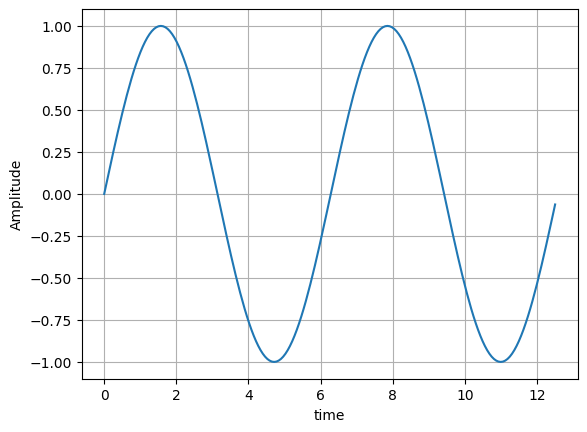

In [14]:
# Make a time series essentially omega is 2*pi*1/T so really this can be a series of angular rotations. 
NPTS = 100
# make 2 cycles
theta = np.arange(0,4.0*np.pi, 2.0*np.pi/NPTS)
A = 1.0
y = A * np.sin(theta)
#
#
plt.plot(theta,y)
plt.grid()
plt.xlabel('time')
plt.ylabel('Amplitude')

<H2> Start adding harmonics to see how it forms. </H2>

Text(0, 0.5, 'Amplitude')

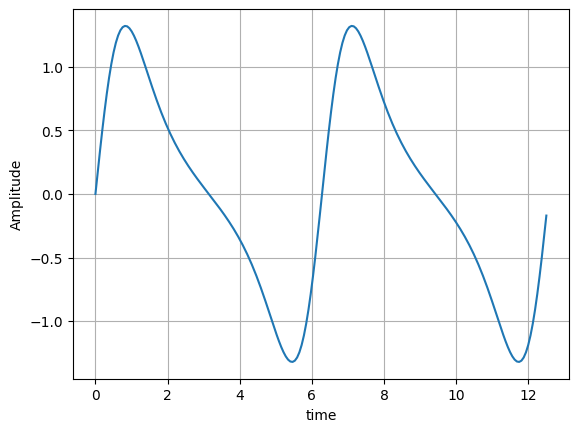

In [42]:
# Make a time series essentially omega is 2*pi*1/T so really this can be a series of angular rotations. 
NPTS = 100
theta = np.arange(0,4.0*np.pi, 2.0*np.pi/NPTS)
A = 1.0
y = 0
for i in range(40):
    y = y + A/math.factorial(i+1) * np.sin((i+1)*theta) 
#
#
plt.plot(theta,y)
plt.grid()
plt.xlabel('time')
plt.ylabel('Amplitude')

This trends to a triangle wave. 

Text(0, 0.5, 'Amplitude')

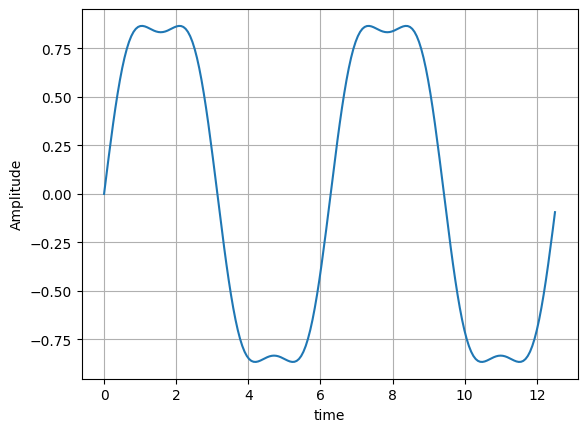

In [36]:
# Make a time series essentially omega is 2*pi*1/T so really this can be a series of angular rotations. 
NPTS = 100
theta = np.arange(0,4.0*np.pi, 2.0*np.pi/NPTS)
A = 1.0
y = 0
for i in range(1,5,2):
    y = y + A/math.factorial(i) * np.sin(i*theta) 
#
#
plt.plot(theta,y)
plt.grid()
plt.xlabel('time')
plt.ylabel('Amplitude')

And the odd components trend to a square wave. 

Text(0, 0.5, 'Amplitude')

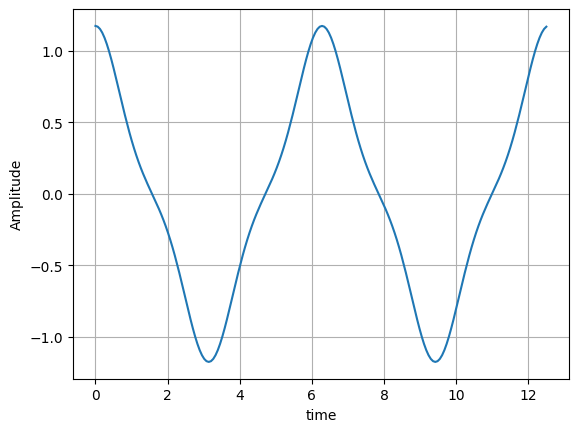

In [40]:
# Make a time series essentially omega is 2*pi*1/T so really this can be a series of angular rotations. 
NPTS = 100
theta = np.arange(0,4.0*np.pi, 2.0*np.pi/NPTS)
A = 1.0
y = 0
for i in range(1,10,2):
    y = y + A/math.factorial(i) * np.cos(i*theta) 
#
#
plt.plot(theta,y)
plt.grid()
plt.xlabel('time')
plt.ylabel('Amplitude')

What happens if we start summing oscillators of slightly different phase. 

Text(0, 0.5, 'Amplitude')

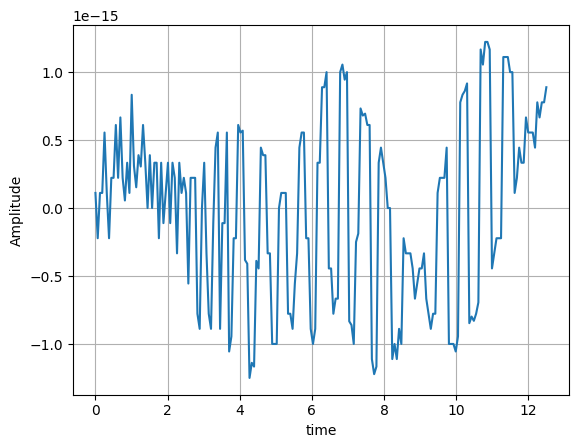

In [43]:
# Make a time series essentially omega is 2*pi*1/T so really this can be a series of angular rotations. 
NPTS = 100
theta = np.arange(0,4.0*np.pi, 2.0*np.pi/NPTS)
A = 1.0
y = 0
NSTEPS = 6
for i in range(1,NSTEPS,2):
    phase = 2.0*np.pi * i/NSTEPS
    y = y + A*np.sin(theta + phase) 
#
#
plt.plot(theta,y)
plt.grid()
plt.xlabel('time')
plt.ylabel('Amplitude')

And now what if the phases were truely random?

Text(0, 0.5, 'Amplitude')

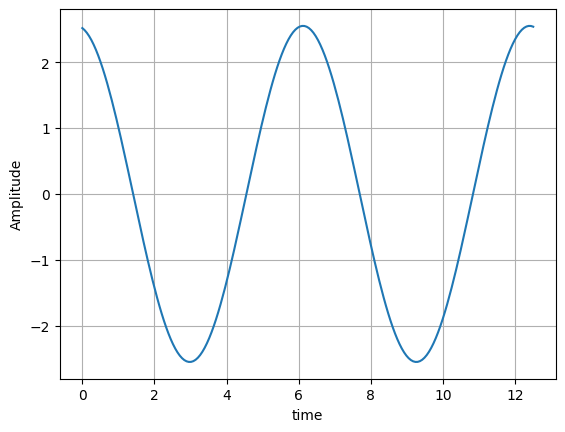

In [53]:
# Number of points in plot
NPTS = 100
#
# Number of oscillators to include 
NSTEPS = 6
#
# Define the parameters of the normal distribution
mean = 0  # Mean of the distribution
std_dev = 1  # Standard deviation of the distribution
size = NPTS*NSTEPS  # Number of random variates to generate
#
# Generate random numbers from a normal distribution
# The 'loc' parameter specifies the mean, and 'scale' specifies the standard deviation.
phase = norm.rvs(loc=mean, scale=std_dev, size=size)
# 
# SIngle frequency vector
# Make a time series essentially omega is 2*pi*1/T so really this can be a series of angular rotations. 
theta = np.arange(0,4.0*np.pi, 2.0*np.pi/NPTS)
A = 1.0
y = 0
for i in range(1,NSTEPS,2):
    #y = y + A/phase[i] *np.sin(theta) 
    y = y + A/phase[i]*np.sin(theta + phase[i]) 
#
#
plt.plot(theta,y)
#plt.hist(phase,bins=40, edgecolor='black')
plt.grid()
plt.xlabel('time')
plt.ylabel('Amplitude')
